# Day 50 — Optimizers and learning rate scheduling

**Learning goals:** follow an update numerically; explain SGD, momentum, Adam and AdamW; distinguish an optimizer from a schedule; place scheduler calls correctly in a PyTorch loop; compare measured training and validation behavior.

Continue the two-moons binary classifier from Day 49. Run top to bottom in Google Colab (CPU is sufficient). The diagrams in the slides are illustrative toy trajectories; the plots here are measured from this notebook's actual classifier. Training outcomes vary with seed and hyperparameters.

## 1. One gradient, one move

A parameter vector $\boldsymbol\theta$ collects all trainable weights and biases. For a minibatch loss $L_t$, let $\mathbf g_t=\nabla_{\boldsymbol\theta}L_t$. SGD updates $\boldsymbol\theta_{t+1}=\boldsymbol\theta_t-\eta_t\mathbf g_t$. The gradient points locally uphill; the minus sign chooses a downhill direction. $\eta_t$ is the learning rate, which scales the move. A minibatch is a noisy sample of the full dataset, so the path may zigzag.

For $\theta_0=3$, $g_0=2$, and $\eta_0=0.1$: $\theta_1=3-0.1(2)=2.8$.

In [1]:
theta, gradient, lr = 3.0, 2.0, 0.1
new_theta = theta - lr * gradient
print(f"{theta:.1f} − {lr:.1f}×{gradient:.1f} = {new_theta:.1f}")
assert abs(new_theta - 2.8) < 1e-12

3.0 − 0.1×2.0 = 2.8


## 2. Momentum: remember recent directions

With PyTorch's simple momentum setting (`dampening=0`, `weight_decay=0`, `nesterov=False`), the buffer is initialized from the **first** gradient; afterwards $\mathbf v_t=\mu\mathbf v_{t-1}+\mathbf g_t$ and $\boldsymbol\theta_{t+1}=\boldsymbol\theta_t-\eta\mathbf v_t$. A consistent direction accumulates; alternating directions can cancel. It can overshoot, so momentum is not automatically better for every problem.

With $g_1=2$, $g_2=1$, $\mu=.9$, $\eta=.1$: $v_1=2$ and $v_2=.9(2)+1=2.8$. Thus the two steps are $0.2$ and $0.28$. Some textbooks use $(1-\mu)g_t$ instead; state the convention before calculating.

In [2]:
mu, eta = .9, .1
gradients = [2., 1.]
buffer, theta = None, 3.
for g in gradients:
    buffer = g if buffer is None else mu * buffer + g
    theta -= eta * buffer
    print(f"gradient={g:.1f}, buffer={buffer:.2f}, parameter={theta:.2f}")
assert abs(theta - 2.52) < 1e-12

gradient=2.0, buffer=2.00, parameter=2.80
gradient=1.0, buffer=2.80, parameter=2.52


## 3. Adam: two moments and bias correction

For each coordinate, Adam keeps a moving gradient mean $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$ and a moving squared-gradient mean $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$. Starting at zero biases the early estimates toward zero, so $\hat m_t=m_t/(1-\beta_1^t)$ and $\hat v_t=v_t/(1-\beta_2^t)$. Then $\theta_{t+1}=\theta_t-\eta\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. Squares and divisions are elementwise. $\epsilon$ avoids division by zero; per-coordinate scaling does not mean the method always trains faster or generalizes better.

First step example: $g_1=2$, $\beta_1=.9$, $\beta_2=.999$, $\eta=.1$. Then $m_1=.2$, $v_1=.004$, $\hat m_1=2$, $\hat v_1=4$, so the update is approximately $-.1$.

In [3]:
import math
g, beta1, beta2, eta, eps = 2., .9, .999, .1, 1e-8
m = (1-beta1)*g
v = (1-beta2)*g*g
m_hat, v_hat = m/(1-beta1), v/(1-beta2)
step = eta*m_hat/(math.sqrt(v_hat)+eps)
print(f"m={m:.3f}, v={v:.3f}, corrected=({m_hat:.1f}, {v_hat:.1f}), step={step:.6f}")
assert abs(step-.1)<1e-8

m=0.200, v=0.004, corrected=(2.0, 4.0), step=0.100000


## 4. AdamW: separate weight decay

AdamW applies a decoupled shrinkage $\theta\leftarrow\theta-\eta\lambda\theta$ as well as the adaptive gradient update. A simple schematic is $\theta_{t+1}=(1-\eta\lambda)\theta_t-\eta\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. With $\theta=3$, $\eta=.1$, $\lambda=.01$, the shrinkage alone is $-.003$. The full step also depends on the gradient. Weight decay is a regularization choice; exclude it (`weight_decay=0`) in the optimizer comparison below to isolate update rules. Do not equate AdamW with adding an L2 gradient to Adam.

In [4]:
theta, eta, wd = 3., .1, .01
print("decoupled shrinkage only:", theta * (1-eta*wd))
assert abs(theta*(1-eta*wd)-2.997)<1e-12

decoupled shrinkage only: 2.997


## 5. Prepare a fair neural-network comparison

Use the same split, architecture, initialization, batch sequence, and epoch budget for each optimizer. Normalize with training statistics only. `BCEWithLogitsLoss` expects raw logits and targets shaped `(N, 1)`; no final sigmoid belongs in the model. We reseed before constructing each model and data loader. This is a controlled illustration, not a universal ranking.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

print("PyTorch:", torch.__version__)
rng = np.random.default_rng(19)
n = 240
t0, t1 = rng.uniform(0, np.pi, n), rng.uniform(0, np.pi, n)
upper = np.column_stack((np.cos(t0), np.sin(t0)))
lower = np.column_stack((1-np.cos(t1), .5-np.sin(t1)))
X_raw = np.vstack((upper, lower)).astype(np.float32)
X_raw += rng.normal(0, .12, X_raw.shape).astype(np.float32)
y_raw = np.r_[np.zeros(n), np.ones(n)].astype(np.float32).reshape(-1,1)
perm = rng.permutation(len(X_raw))
train_i, val_i = perm[:384], perm[384:]
mean, std = X_raw[train_i].mean(0), X_raw[train_i].std(0)
X_train = torch.tensor((X_raw[train_i]-mean)/std)
X_val = torch.tensor((X_raw[val_i]-mean)/std)
y_train, y_val = torch.tensor(y_raw[train_i]), torch.tensor(y_raw[val_i])
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)
assert X_train.shape == (384,2) and y_train.shape == (384,1)

PyTorch: 2.6.0
torch.Size([384, 2]) torch.Size([96, 2]) torch.Size([384, 1]) torch.Size([96, 1])


In [6]:
def build_model():
    return nn.Sequential(nn.Linear(2,16), nn.Tanh(),
                         nn.Linear(16,16), nn.Tanh(), nn.Linear(16,1))

def evaluate(model, criterion):
    model.eval()
    with torch.no_grad():
        return criterion(model(X_val), y_val).item()

print(build_model())

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): Tanh()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


## 6. Scheduler mechanics and the meaning of “step”

A schedule changes the optimizer's `param_groups[0]['lr']`; it does not replace gradients or `optimizer.step()`.

| Schedule | Typical control | Call location |
|---|---|---|
| Constant | fixed $\eta$ | no scheduler |
| StepLR | multiply by $\gamma$ every `step_size` epochs | after all batch updates, once per epoch |
| CosineAnnealingLR | smoothly move from $\eta_{max}$ toward $\eta_{min}$ over `T_max` calls | after all batch updates, once per epoch in this example |
| ReduceLROnPlateau | reduce after validation metric stops improving | after validation, pass `val_loss` |
| OneCycleLR | rise then fall across total training batches | after **each** batch update |

For StepLR with $\eta_0=.12$, `step_size=12`, $\gamma=.5$: epochs 1–12 use .12, 13–24 use .06, and 25–36 use .03, because we call `scheduler.step()` at the end of each epoch. Cosine without restarts: $\eta_t=\eta_{min}+\frac12(\eta_{max}-\eta_{min})(1+\cos(\pi t/T_{max}))$ for $0\le t\le T_{max}$. `T_max` counts **calls** to `.step()`, not intrinsically epochs.

In [7]:
base, gamma, size = .12, .5, 12
print({epoch:base*gamma**((epoch-1)//size) for epoch in [1,12,13,24,25]})
assert base*gamma**((13-1)//size)==.06

def cosine_value(t, total, maximum=.12, minimum=.005):
    return minimum + .5*(maximum-minimum)*(1+math.cos(math.pi*t/total))
print([round(cosine_value(t,40),5) for t in [0,10,20,30,40]])

{1: 0.12, 12: 0.12, 13: 0.06, 24: 0.06, 25: 0.03}
[0.12, 0.10316, 0.0625, 0.02184, 0.005]


## 7. Run controlled experiments

The helper logs the learning rate **used during** each epoch before stepping the scheduler. `ReduceLROnPlateau` consumes validation loss, never training loss. Each run uses identical initial weights and batch order. The candidate learning rates are practical teaching choices, not matched optimum settings. We compare validation results as well as training results.

In [8]:
def train_run(optimizer_name="sgd", schedule="constant", epochs=40):
    torch.manual_seed(7)
    model = build_model()
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(X_train,y_train), batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(31))
    if optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=.12)
    elif optimizer_name == "momentum":
        optimizer = torch.optim.SGD(model.parameters(), lr=.12, momentum=.9)
    elif optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=.01, weight_decay=0.)
    else:
        raise ValueError(optimizer_name)
    if schedule == "constant":
        scheduler = None
    elif schedule == "step":
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=12, gamma=.5)
    elif schedule == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=.005)
    elif schedule == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=.5, patience=4)
    else:
        raise ValueError(schedule)
    history = {"train":[],"val":[],"lr":[]}
    for epoch in range(epochs):
        model.train()
        history["lr"].append(optimizer.param_groups[0]["lr"])
        total = 0.
        for xb,yb in loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total += loss.item()*len(xb)
        history["train"].append(total/len(X_train))
        val_loss = evaluate(model, criterion)
        history["val"].append(val_loss)
        if schedule == "plateau":
            scheduler.step(val_loss)
        elif scheduler is not None:
            scheduler.step()
    return model, history

optimizer_runs = {name: train_run(name) for name in ["sgd","momentum","adamw"]}
for name, (_,h) in optimizer_runs.items():
    print(name, "final train",round(h["train"][-1],4),"final validation",round(h["val"][-1],4))

sgd final train 0.1938 final validation 0.2147
momentum final train 0.0167 final validation 0.0114
adamw final train 0.019 final validation 0.0132


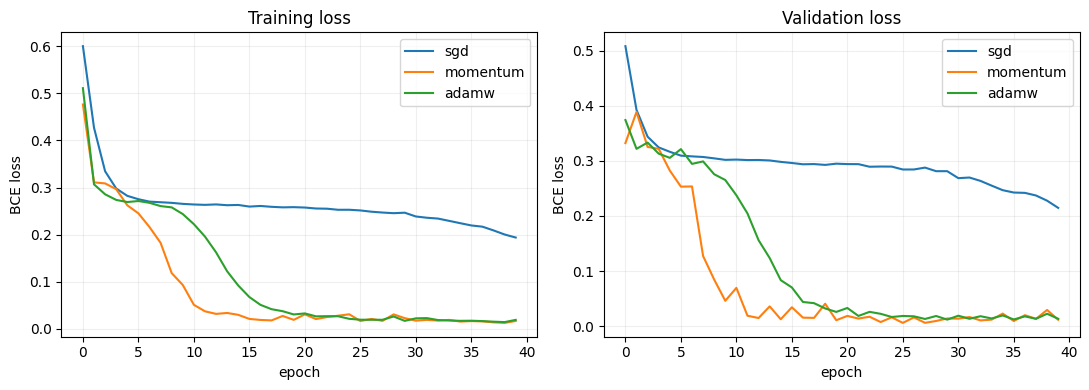

In [9]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name,(_,h) in optimizer_runs.items():
    axes[0].plot(h["train"],label=name)
    axes[1].plot(h["val"],label=name)
for ax,title in zip(axes,["Training loss","Validation loss"]):
    ax.set(xlabel="epoch",ylabel="BCE loss",title=title)
    ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()

**Read the evidence:** a lower training loss alone does not prove better generalization. Here each optimizer gets one chosen learning rate; tune comparable budgets on validation data before making broader claims.

## 8. Compare schedules on one optimizer

Keep the same model, momentum optimizer, starting rate, and 40 epochs. The measured learning-rate curve is a useful guard against off-by-one mistakes. Plateau may stay unchanged if validation keeps improving; that is correct behavior.

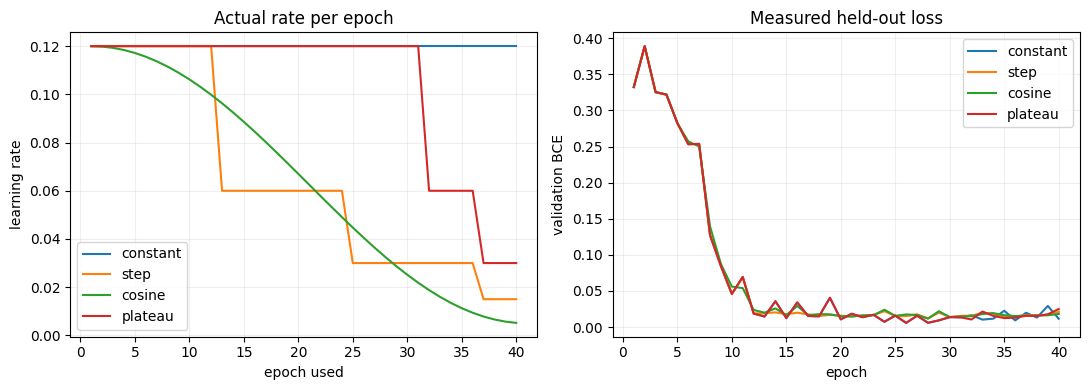

step: first 14 rates: [0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.12 0.06 0.06]


In [10]:
schedule_runs = {name:train_run("momentum",name) for name in ["constant","step","cosine","plateau"]}
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,(_,h) in schedule_runs.items():
    axes[0].plot(range(1,41),h["lr"],label=name)
    axes[1].plot(range(1,41),h["val"],label=name)
axes[0].set(xlabel="epoch used",ylabel="learning rate",title="Actual rate per epoch")
axes[1].set(xlabel="epoch",ylabel="validation BCE",title="Measured held-out loss")
for ax in axes: ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.show()
print("step: first 14 rates:",np.round(schedule_runs["step"][1]["lr"][:14],4))
assert np.allclose(schedule_runs["step"][1]["lr"][:12],.12)
assert np.isclose(schedule_runs["step"][1]["lr"][12],.06)

## 9. OneCycleLR uses batch time

Set `steps_per_epoch=len(loader)` and `epochs` to define the total batch steps. Instantiate a fresh optimizer and call `scheduler.step()` immediately **after** each `optimizer.step()`. The rate first rises toward `max_lr`, then falls. The schedule may also vary momentum. Avoid adding an epoch-level call. This is a demonstration, not the same starting-rate comparison above.

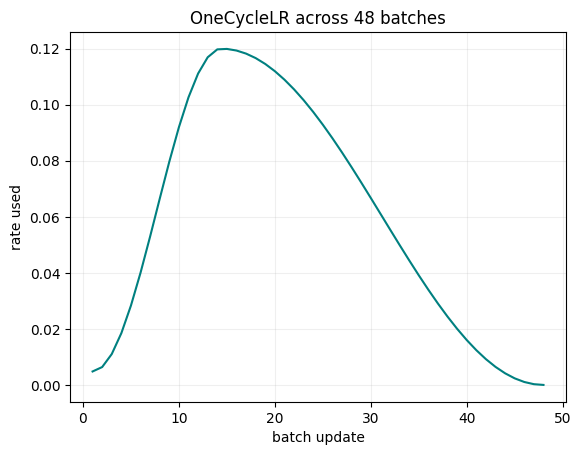

In [11]:
torch.manual_seed(7)
cycle_model = build_model()
cycle_loader = DataLoader(TensorDataset(X_train,y_train),batch_size=32,shuffle=True,
                          generator=torch.Generator().manual_seed(31))
cycle_opt = torch.optim.SGD(cycle_model.parameters(),lr=.02,momentum=.9)
cycle = torch.optim.lr_scheduler.OneCycleLR(cycle_opt,max_lr=.12,epochs=4,
                                            steps_per_epoch=len(cycle_loader))
cycle_rates=[]
cycle_criterion=nn.BCEWithLogitsLoss()
for epoch in range(4):
    cycle_model.train()
    for xb,yb in cycle_loader:
        cycle_rates.append(cycle_opt.param_groups[0]["lr"])
        cycle_opt.zero_grad()
        cycle_criterion(cycle_model(xb),yb).backward()
        cycle_opt.step()
        cycle.step()
plt.plot(range(1,len(cycle_rates)+1),cycle_rates,color="teal")
plt.xlabel("batch update");plt.ylabel("rate used");plt.title("OneCycleLR across 48 batches")
plt.grid(alpha=.2);plt.show()
assert len(cycle_rates)==4*len(cycle_loader)==48

## 10. Checkpoint the complete training state

Weights, momentum/Adam moments, and scheduler position live in different state dictionaries. For an exact resume, also preserve relevant random-number state, sampler order, and epoch/batch position. This short example stores the three core states in memory to keep the course folder clean. To resume, create compatible model, optimizer, scheduler objects, then load all three states. If using a stateful sampler or mixed precision, save their states too.

In [12]:
import io
model,h = schedule_runs["step"]
# A fresh short run shows the state-dict pattern without creating a file.
resume_model=build_model()
resume_opt=torch.optim.SGD(resume_model.parameters(),lr=.12,momentum=.9)
resume_sched=torch.optim.lr_scheduler.StepLR(resume_opt,step_size=12,gamma=.5)
record={"model":resume_model.state_dict(),"optimizer":resume_opt.state_dict(),
        "scheduler":resume_sched.state_dict(),"epoch":0}
buffer=io.BytesIO();torch.save(record,buffer);buffer.seek(0)
try:
    restored=torch.load(buffer,map_location="cpu",weights_only=True)
except TypeError: # older PyTorch releases have no weights_only argument
    buffer.seek(0);restored=torch.load(buffer,map_location="cpu")
other_model=build_model()
other_opt=torch.optim.SGD(other_model.parameters(),lr=.12,momentum=.9)
other_sched=torch.optim.lr_scheduler.StepLR(other_opt,step_size=12,gamma=.5)
other_model.load_state_dict(restored["model"])
other_opt.load_state_dict(restored["optimizer"])
other_sched.load_state_dict(restored["scheduler"])
print("restored epoch",restored["epoch"],"lr",other_opt.param_groups[0]["lr"])

restored epoch 0 lr 0.12


## 11. Summary and primary references

- **SGD:** step in the negative minibatch gradient direction. **Momentum:** incorporate previous directions. **Adam:** bias-correct two running moments and scale each coordinate. **AdamW:** adaptive step plus decoupled weight decay.
- **Scheduler:** determines the learning rate over time. StepLR and cosine usually advance once per epoch in our loop; plateau sees the validation metric; OneCycle advances every batch.
- Record the rate used for each update and compare held-out outcomes. Seeded toy runs illustrate behavior rather than establish a universal optimizer winner.

Official PyTorch references: [SGD](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html) · [Adam](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html) · [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html) · [StepLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html) · [CosineAnnealingLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html) · [ReduceLROnPlateau](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html) · [OneCycleLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html).